#### Tarea 5
## Resde neuronales convucionales (CNN)

### Introducción
Las redes neuronales convolucionales son un tipo de red neuronal diseñada especialmente para analizar imágenes y otros datos con estructura espacial, como videos o mapas. Utilizan datos tridimensionales para tareas de clasificación de imágenes y reconocimiento de objetos. (¿Qué Son las Redes Neuronales Convolucionales? | IBM, 2026) 

El objectivo de esta tarea es diseñar y evaluar una red neuronal convolucional (CNN) que utilice Global Average Pooling (GAP) para clasificar imágenes del conjunto de datos MNIST, buscando superar el 95% de exactitud en validación con menos de 54 330 parámetros entrenables.

Para ello, se explorarán diferentes arquitecturas, modificando características como el número de filtros, la profundidad y las operaciones de pooling. Se seleccionará el modelo con menor cantidad de parámetros entre aquellos que cumplan los requisitos establecidos.

Finalmente, se comparará su desempeño con las arquitecturas de referencia CNN + Flatten y CNN + GAP, evaluando su capacidad para reconocer dígitos desplazados 0, 2 y 4 píxeles.

In [4]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from tensorflow import keras

### 1. Preparación de los datos

Se utilizará el conjunto de datos MNIST, compuesto por imágenes de dígitos manuscritos del 0 al 9.

Para mantener las condiciones de los experimentos originales, se utilizarán 8 000 imágenes de entrenamiento, 1 500 de validación y 2 000 de prueba, con una semilla de 42.

Las imágenes originales de 28 × 28 píxeles se normalizarán al intervalo [0, 1] y se les agregará un margen negro de cuatro píxeles en cada lado, obteniendo imágenes de 36 × 36 píxeles. Este margen permitirá evaluar posteriormente el efecto de desplazar los dígitos.

In [5]:
# Configuración de los experimentos
SEMILLA = 42
N_ENT = 8000
N_VAL = 1500
N_PRUEBA = 2000
MARGEN = 4

keras.utils.set_random_seed(SEMILLA)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False
})


In [6]:
# Cargar MNIST
(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()

# Partición estratificada de entrenamiento y validación
i_ent, i_val = train_test_split(
    np.arange(len(y_des)),
    train_size=N_ENT,
    test_size=N_VAL,
    stratify=y_des,
    random_state=SEMILLA
)

# Selección estratificada del conjunto de prueba
i_prueba, _ = train_test_split(
    np.arange(len(y_test)),
    train_size=N_PRUEBA,
    stratify=y_test,
    random_state=SEMILLA
)

# Agregar margen negro y normalizar
def preparar_imagenes(imagenes):
    imagenes = np.pad(
        imagenes,
        ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN))
    )
    return imagenes[..., None].astype(np.float32) / 255.0

# Preparar los conjuntos
X_ent = preparar_imagenes(x_des[i_ent])
y_ent = y_des[i_ent]

X_val = preparar_imagenes(x_des[i_val])
y_val = y_des[i_val]

X_prueba = preparar_imagenes(x_test[i_prueba])
y_prueba = y_test[i_prueba]

FORMA = X_ent.shape[1:]

# Verificar dimensiones
for nombre, X in [
    ("Entrenamiento", X_ent),
    ("Validación", X_val),
    ("Prueba", X_prueba)
]:
    print(f"{nombre}: {X.shape}")


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Entrenamiento: (8000, 36, 36, 1)
Validación: (1500, 36, 36, 1)
Prueba: (2000, 36, 36, 1)


### 2. Modelos de referencia

Se utilizarán dos arquitecturas CNN como punto de comparación:

- **CNN + Flatten:** conserva la información espacial de los mapas de características al convertirlos en un vector antes de la clasificación.
- **CNN + GAP:** utiliza Global Average Pooling para promediar espacialmente cada mapa de características, reduciendo considerablemente el número de parámetros.

In [7]:
referencias = pd.DataFrame({
    "Modelo": ["CNN + Flatten", "CNN + GAP"],
    "Parámetros": [54330, 2650],
    "Validación (%)": [96.87, 44.07],
    "Prueba 0 px (%)": [97.15, 46.35],
    "Prueba 4 px (%)": [37.21, 46.38]
})

display(referencias)

,Modelo,Parámetros,Validación (%),Prueba 0 px (%),Prueba 4 px (%)
0,CNN + Flatten,54330,96.87,97.15,37.21
1,CNN + GAP,2650,44.07,46.35,46.38


#### 2.1. Arquitecturas base

Ambos modelos utilizan dos capas convolucionales de 16 filtros con kernels de 3×3, activación ReLU y una capa MaxPooling de 2×2. La única diferencia entre las arquitecturas es la operación utilizada antes de la clasificación:

- **Flatten:** transforma los mapas de características en un vector que conserva su información espacial.
- **Global Average Pooling (GAP):** calcula el promedio de cada mapa de características, reduciendo la cantidad de parámetros entrenables.

Finalmente, ambos modelos utilizan una capa Dense de 10 neuronas con activación Softmax para clasificar los dígitos.

In [8]:
# Configuración del entrenamiento
CAPAS = (16, 16)
LOTE = 128
EPOCAS = 20
TASA = 0.001

def crear_cnn(filtros=CAPAS, cabeza="flatten"):
    capas = [keras.Input(shape=FORMA)]

    # Capas convolucionales
    for i, n_filtros in enumerate(filtros):
        capas.append(
            keras.layers.Conv2D(
                filters=n_filtros,
                kernel_size=3,
                padding="same",
                activation="relu",
                name=f"conv_{i+1}"
            )
        )

    # Pooling
    capas.append(
        keras.layers.MaxPooling2D(
            pool_size=2,
            name="pool"
        )
    )

    # Capa de reducción
    if cabeza == "flatten":
        capas.append(keras.layers.Flatten(name="vector"))
    elif cabeza == "gap":
        capas.append(
            keras.layers.GlobalAveragePooling2D(name="vector")
        )
    else:
        raise ValueError("Cabeza no válida")

    # Clasificación
    capas.append(
        keras.layers.Dense(
            10,
            activation="softmax",
            name="salida"
        )
    )

    return keras.Sequential(capas, name=f"cnn_{cabeza}")

In [9]:
modelo_flatten = crear_cnn(cabeza="flatten")
modelo_gap_base = crear_cnn(cabeza="gap")

print("CNN + Flatten")
modelo_flatten.summary()

print("\nCNN + GAP")
modelo_gap_base.summary()

print("\nParámetros entrenables:")
print("Flatten:", sum(
    np.prod(p.shape) for p in modelo_flatten.trainable_weights
))
print("GAP:", sum(
    np.prod(p.shape) for p in modelo_gap_base.trainable_weights
))

CNN + Flatten


Model: "cnn_flatten"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 36, 36, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 36, 36, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool (MaxPooling2D)             │ (None, 18, 18, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector (Flatten)                │ (None, 5184)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │        51,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,330 (212.23 KB)

 Trainable params: 54,330 (212.23 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 2,650 (10.35 KB)

 Trainable params: 2,650 (10.35 KB)

 Non-trainable params: 0 (0.00 B)


Parámetros entrenables:
Flatten: 54330
GAP: 2650


#### 2.2. Entrenamiento de los modelos base

Se entrenarán ambas arquitecturas durante 20 épocas utilizando el optimizador Adam, una tasa de aprendizaje de 0.001 y lotes de 128 imágenes.

Se utilizará la función de pérdida *sparse categorical crossentropy*, adecuada para problemas de clasificación multiclase con etiquetas enteras.

Para mantener una comparación justa, ambos modelos utilizarán las mismas particiones de datos, configuración de entrenamiento y semilla aleatoria.

La exactitud de validación permitirá comparar el desempeño de las arquitecturas sin utilizar todavía el conjunto de prueba.

In [10]:
def entrenar_modelo(modelo, semilla=SEMILLA):
    keras.utils.set_random_seed(semilla)

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    historial = modelo.fit(
        X_ent,
        y_ent,
        validation_data=(X_val, y_val),
        epochs=EPOCAS,
        batch_size=LOTE,
        verbose=0,
        shuffle=True
    )

    return historial

In [11]:
# CNN + Flatten
keras.utils.set_random_seed(SEMILLA)
modelo_flatten = crear_cnn(cabeza="flatten")

print("Entrenando CNN + Flatten...")
hist_flatten = entrenar_modelo(modelo_flatten)

# CNN + GAP
keras.utils.set_random_seed(SEMILLA)
modelo_gap_base = crear_cnn(cabeza="gap")

print("Entrenando CNN + GAP...")
hist_gap_base = entrenar_modelo(modelo_gap_base)

# Resultados
resultados_base = pd.DataFrame({
    "Modelo": ["CNN + Flatten", "CNN + GAP"],
    "Parámetros": [
        modelo_flatten.count_params(),
        modelo_gap_base.count_params()
    ],
    "Validación final (%)": [
        hist_flatten.history["val_accuracy"][-1] * 100,
        hist_gap_base.history["val_accuracy"][-1] * 100
    ]
})

display(resultados_base.round(2))

Entrenando CNN + Flatten...
Entrenando CNN + GAP...


,Modelo,Parámetros,Validación final (%)
0,CNN + Flatten,54330,96.47
1,CNN + GAP,2650,41.20


#### 2.3. Resultados de los modelos base

Después de 20 épocas de entrenamiento, la CNN con Flatten obtuvo una exactitud de validación del 96.47% utilizando 54 330 parámetros entrenables, mientras que la CNN con GAP alcanzó únicamente el 41.20% con 2 650 parámetros.

Los muestran una diferencia importante entre ambas arquitecturas. Aunque GAP permite reducir aproximadamente un 95.12 % de los parámetros, esta reducción viene acompañada de una pérdida considerable de exactitud. Por ello, se explorarán arquitecturas con mayor profundidad, diferentes cantidades de filtros y operaciones de pooling para mejorar su capacidad de clasificación sin perder su ventaja en eficiencia.

### 3. Exploración de arquitecturas con Global Average Pooling

Se explorarán diferentes arquitecturas CNN con GAP para mejorar la exactitud del modelo original (41.20%) sin superar los 54 330 parámetros entrenables de Flatten.

Se modificarán la profundidad de la red, el número de filtros y las operaciones de pooling, manteniendo las mismas particiones, semilla y configuración de entrenamiento de 20 épocas. La selección se realizará utilizando exclusivamente los resultados de validación.

#### 3.1. Exploración inicial

Se evaluarán seis variantes modificando el número de capas convolucionales, la cantidad de filtros y el tipo de pooling. Se incluirán comparaciones donde cambie una sola característica para analizar su efecto sobre la exactitud.

In [31]:
def crear_cnn_gap(filtros, pooling="max"):
    capas = [keras.Input(shape=FORMA)]

    for n_filtros in filtros:
        capas.append(
            keras.layers.Conv2D(
                n_filtros,
                kernel_size=3,
                padding="same",
                activation="relu"
            )
        )

    if pooling == "max":
        capas.append(keras.layers.MaxPooling2D(2))
    elif pooling == "average":
        capas.append(keras.layers.AveragePooling2D(2))
    elif pooling != "sin":
        raise ValueError("Tipo de pooling no válido")

    capas.extend([
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(10, activation="softmax")
    ])

    return keras.Sequential(capas)


variantes_gap = {
    "GAP 1": {"filtros": (16, 16, 16), "pooling": "max"},
    "GAP 2": {"filtros": (16, 16, 16, 16), "pooling": "max"},
    "GAP 3": {"filtros": (16, 32, 32), "pooling": "max"},
    "GAP 4": {"filtros": (16, 32, 32, 32), "pooling": "max"},
    "GAP 5": {"filtros": (16, 32, 32, 32), "pooling": "average"},
    "GAP 6": {"filtros": (16, 32, 32, 32), "pooling": "sin"}
}

In [32]:
resultados_gap = []
modelos_gap = {}
historiales_gap = {}

for nombre, config in variantes_gap.items():
    print(f"\nEntrenando {nombre}...")

    keras.utils.set_random_seed(SEMILLA)
    modelo = crear_cnn_gap(**config)
    historial = entrenar_modelo(modelo)

    modelos_gap[nombre] = modelo
    historiales_gap[nombre] = historial.history

    resultados_gap.append({
        "Modelo": nombre,
        "Filtros": str(config["filtros"]),
        "Pooling": config["pooling"],
        "Parámetros": modelo.count_params(),
        "Validación (%)": historial.history["val_accuracy"][-1] * 100
    })

tabla_gap = pd.DataFrame(resultados_gap)

display(tabla_gap.round(2))



Entrenando GAP 1...

Entrenando GAP 2...

Entrenando GAP 3...

Entrenando GAP 4...

Entrenando GAP 5...

Entrenando GAP 6...


,Modelo,Filtros,Pooling,Parámetros,Validación (%)
0,GAP 1,"(16, 16, 16)",max,4970,54.87
1,GAP 2,"(16, 16, 16, 16)",max,7290,64.47
2,GAP 3,"(16, 32, 32)",max,14378,62.13
3,GAP 4,"(16, 32, 32, 32)",max,23626,80.47
4,GAP 5,"(16, 32, 32, 32)",average,23626,77.80
5,GAP 6,"(16, 32, 32, 32)",sin,23626,77.47


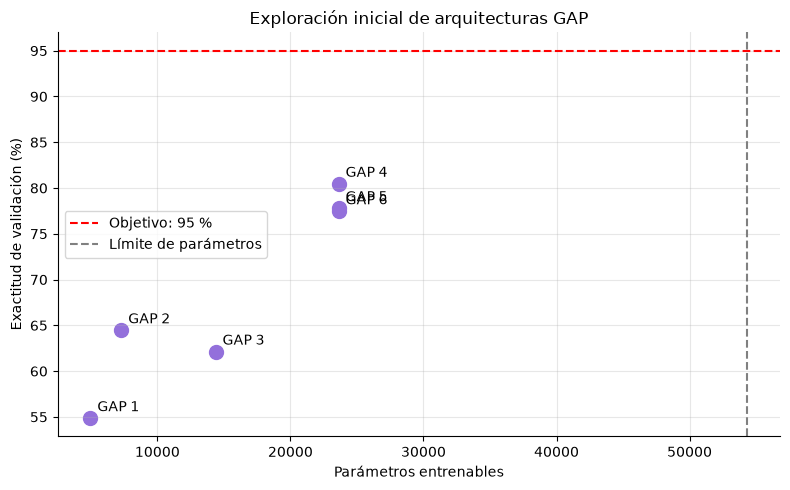

In [33]:
plt.figure(figsize=(8, 5))

plt.scatter(
    tabla_gap["Parámetros"],
    tabla_gap["Validación (%)"],
    color="mediumpurple",
    s=100
)

for _, fila in tabla_gap.iterrows():
    plt.annotate(
        fila["Modelo"],
        (fila["Parámetros"], fila["Validación (%)"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(
    95,
    color="red",
    linestyle="--",
    label="Objetivo: 95 %"
)

plt.axvline(
    54330,
    color="gray",
    linestyle="--",
    label="Límite de parámetros"
)

plt.xlabel("Parámetros entrenables")
plt.ylabel("Exactitud de validación (%)")
plt.title("Exploración inicial de arquitecturas GAP")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Ninguna de las seis arquitecturas alcanzó el 95 % de exactitud en validación. Sin embargo, todas mejoraron el desempeño del GAP original, y GAP 4 obtuvo el mejor resultado, con **80.47 % de exactitud y 23 626 parámetros entrenables**.

Las comparaciones mostraron que aumentar la profundidad de la red favoreció el desempeño, mientras que incrementar únicamente el número de filtros no garantizó mejores resultados. Además, MaxPooling obtuvo una exactitud ligeramente superior a AveragePooling y a la configuración sin pooling.

Estos resultados sugirieron que sería necesario explorar otras modificaciones arquitectónicas para alcanzar el objetivo establecido.

#### 3.2. Distribución de las capas MaxPooling

A partir de GAP 4, que obtuvo la mayor exactitud de la exploración inicial (80.47%), se evaluará si modificar la ubicación de las operaciones MaxPooling permite mejorar el desempeño.

Se probarán cuatro variantes con los mismos filtros (16, 32, 32, 32) y 23 626 parámetros entrenables, cambiando únicamente las posiciones donde se aplica MaxPooling. De esta manera, se podrá analizar el efecto de su distribución sin modificar la capacidad del modelo en términos de parámetros.

In [34]:
def crear_cnn_gap_bloques(filtros, pooling_despues):
    capas = [keras.Input(shape=FORMA)]

    for i, n_filtros in enumerate(filtros, start=1):
        capas.append(
            keras.layers.Conv2D(
                n_filtros,
                kernel_size=3,
                padding="same",
                activation="relu"
            )
        )

        if i in pooling_despues:
            capas.append(keras.layers.MaxPooling2D(2))

    capas.extend([
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dense(10, activation="softmax")
    ])

    return keras.Sequential(capas)


variantes_bloques = {
    "GAP 7":  {"filtros": (16, 32, 32, 32), "pooling_despues": (2, 4)},
    "GAP 8":  {"filtros": (16, 32, 32, 32), "pooling_despues": (1, 3)},
    "GAP 9":  {"filtros": (16, 32, 32, 32), "pooling_despues": (2,)},
    "GAP 10": {"filtros": (16, 32, 32, 32), "pooling_despues": (1, 2, 3)}
}

In [35]:
resultados_bloques = []
modelos_bloques = {}
historiales_bloques = {}

for nombre, config in variantes_bloques.items():
    print(f"Entrenando {nombre}...")

    keras.utils.set_random_seed(SEMILLA)
    modelo = crear_cnn_gap_bloques(**config)
    historial = entrenar_modelo(modelo)

    modelos_bloques[nombre] = modelo
    historiales_bloques[nombre] = historial.history

    resultados_bloques.append({
        "Modelo": nombre,
        "Filtros": str(config["filtros"]),
        "Pooling después de": str(config["pooling_despues"]),
        "Parámetros": modelo.count_params(),
        "Validación (%)": historial.history["val_accuracy"][-1] * 100
    })

tabla_bloques = pd.DataFrame(resultados_bloques)

# Comparación con GAP 4 de la sección anterior
referencia_gap4 = tabla_gap.loc[
    tabla_gap["Modelo"] == "GAP 4",
    ["Modelo", "Parámetros", "Validación (%)"]
]

comparacion_pooling = pd.concat([
    referencia_gap4,
    tabla_bloques[["Modelo", "Parámetros", "Validación (%)"]]
], ignore_index=True)

display(
    comparacion_pooling.sort_values(
        "Validación (%)", ascending=False
    ).round(2)
)

Entrenando GAP 7...
Entrenando GAP 8...
Entrenando GAP 9...
Entrenando GAP 10...


,Modelo,Parámetros,Validación (%)
4,GAP 10,23626,95.67
2,GAP 8,23626,93.27
1,GAP 7,23626,92.27
3,GAP 9,23626,89.40
0,GAP 4,23626,80.47


La modificación de las posiciones de MaxPooling permitió mejorar considerablemente la exactitud sin aumentar el número de parámetros. GAP 10 obtuvo el mejor resultado, con **95.67 % de exactitud en validación y 23 626 parámetros entrenables**, cumpliendo ambos requisitos de la tarea.

En comparación con GAP 4, GAP 10 mejoró la exactitud en **15.20 puntos porcentuales**, a pesar de utilizar los mismos filtros y parámetros. Esto mostró que la distribución de las operaciones de pooling tuvo un efecto importante sobre el desempeño.

Aunque GAP 10 ya cumplió el objetivo, todavía será posible explorar arquitecturas más compactas para intentar reducir el número de parámetros manteniendo una exactitud superior al 95%.

#### 3.3. Optimización y selección de la arquitectura final

Después de identificar una distribución de pooling que permitió superar el 95% de exactitud, se buscará reducir el número de parámetros entrenables.

Se mantendrán las cuatro capas convolucionales y las operaciones MaxPooling después de las primeras tres, modificando únicamente la cantidad de filtros. Se evaluarán nueve variantes adicionales para seleccionar la arquitectura más compacta que conserve una exactitud de validación superior al 95%.

In [36]:
variantes_compactas = {
    "GAP 11": (8, 16, 16, 16),
    "GAP 12": (8, 16, 24, 24),
    "GAP 13": (8, 24, 24, 24),
    "GAP 14": (12, 24, 24, 24),
    "GAP 15": (12, 32, 32, 32),
    "GAP 16": (8, 20, 24, 24),
    "GAP 17": (8, 24, 20, 24),
    "GAP 18": (8, 24, 24, 20),
    "GAP 19": (8, 20, 20, 24)
}

# Se conserva la distribución de pooling de GAP 10
POOLING_OPTIMO = (1, 2, 3)

In [37]:
resultados_compactos = []
modelos_compactos = {}
historiales_compactos = {}

for nombre, filtros in variantes_compactas.items():
    print(f"Entrenando {nombre}...")

    keras.utils.set_random_seed(SEMILLA)

    modelo = crear_cnn_gap_bloques(
        filtros=filtros,
        pooling_despues=POOLING_OPTIMO
    )

    historial = entrenar_modelo(modelo)

    modelos_compactos[nombre] = modelo
    historiales_compactos[nombre] = historial.history

    resultados_compactos.append({
        "Modelo": nombre,
        "Filtros": str(filtros),
        "Parámetros": modelo.count_params(),
        "Validación (%)": historial.history["val_accuracy"][-1] * 100
    })

tabla_compactos = pd.DataFrame(resultados_compactos)

display(tabla_compactos.round(2))

Entrenando GAP 11...
Entrenando GAP 12...
Entrenando GAP 13...
Entrenando GAP 14...
Entrenando GAP 15...
Entrenando GAP 16...
Entrenando GAP 17...
Entrenando GAP 18...
Entrenando GAP 19...


,Modelo,Filtros,Parámetros,Validación (%)
0,GAP 11,"(8, 16, 16, 16)",6058,93.73
1,GAP 12,"(8, 16, 24, 24)",10186,94.47
2,GAP 13,"(8, 24, 24, 24)",12498,96.07
3,GAP 14,"(12, 24, 24, 24)",13402,95.73
4,GAP 15,"(12, 32, 32, 32)",22434,96.53
5,GAP 16,"(8, 20, 24, 24)",11342,95.33
6,GAP 17,"(8, 24, 20, 24)",10766,94.87
7,GAP 18,"(8, 24, 24, 20)",11590,95.20
8,GAP 19,"(8, 20, 20, 24)",9754,95.40


In [38]:
# Reunir los resultados de todas las variantes
tabla_general = pd.concat([
    tabla_gap[["Modelo", "Parámetros", "Validación (%)"]],
    tabla_bloques[["Modelo", "Parámetros", "Validación (%)"]],
    tabla_compactos[["Modelo", "Parámetros", "Validación (%)"]]
], ignore_index=True)

# Identificar las arquitecturas que cumplen ambos requisitos
tabla_general["Cumple"] = (
    (tabla_general["Validación (%)"] > 95) &
    (tabla_general["Parámetros"] < modelo_flatten.count_params())
)

# Ordenar por número de parámetros
tabla_general = tabla_general.sort_values(
    "Parámetros"
).reset_index(drop=True)

display(tabla_general.round(2))

# Seleccionar el modelo más compacto que cumple
candidatos = tabla_general[tabla_general["Cumple"]]

if candidatos.empty:
    raise ValueError("Ninguna arquitectura cumple ambos requisitos.")

nombre_seleccionado = candidatos.iloc[0]["Modelo"]

todos_modelos_gap = {
    **modelos_gap,
    **modelos_bloques,
    **modelos_compactos
}

modelo_gap_seleccionado = todos_modelos_gap[nombre_seleccionado]

parametros_flatten = modelo_flatten.count_params()
parametros_gap = modelo_gap_seleccionado.count_params()

ahorro = parametros_flatten - parametros_gap
reduccion = ahorro / parametros_flatten * 100

print(f"Modelo seleccionado: {nombre_seleccionado}")
print(f"Parámetros: {parametros_gap:,}")
print(f"Ahorro: {ahorro:,} parámetros ({reduccion:.2f} %)")

modelo_gap_seleccionado.summary()

,Modelo,Parámetros,Validación (%),Cumple
0,GAP 1,4970,54.87,False
1,GAP 11,6058,93.73,False
2,GAP 2,7290,64.47,False
3,GAP 19,9754,95.40,True
4,GAP 12,10186,94.47,False
5,GAP 17,10766,94.87,False
6,GAP 16,11342,95.33,True
7,GAP 18,11590,95.20,True
8,GAP 13,12498,96.07,True
9,GAP 14,13402,95.73,True


Modelo seleccionado: GAP 19
Parámetros: 9,754
Ahorro: 44,576 parámetros (82.05 %)


Model: "sequential_56"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_70 (Conv2D)              │ (None, 36, 36, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_44 (MaxPooling2D) │ (None, 18, 18, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_71 (Conv2D)              │ (None, 18, 18, 20)     │         1,460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_45 (MaxPooling2D) │ (None, 9, 9, 20)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_72 (Conv2D)              │ (None, 9, 9, 20)       │         3,620 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_46 (MaxPooling2D) │ (None, 4, 4, 20)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_73 (Conv2D)              │ (None, 4, 4, 24)       │         4,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_56     │ (None, 24)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 10)             │           250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,264 (114.32 KB)

 Trainable params: 9,754 (38.10 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 19,510 (76.21 KB)

La reducción del número de filtros permitió obtener arquitecturas considerablemente más compactas sin perder la exactitud alcanzada con GAP 10.

Entre las 19 variantes evaluadas, se seleccionó **GAP 19**, ya que fue la arquitectura con menos parámetros que superó el 95 % de exactitud en validación. Obtuvo **95.40 % de exactitud con 9 754 parámetros entrenables**.

En comparación con la CNN con Flatten, GAP 19 permitió ahorrar **44 576 parámetros**, equivalentes a una reducción del **82.05 %**. Estos resultados mostraron que fue posible reducir considerablemente el tamaño del modelo manteniendo una buena capacidad de clasificación.

### 4. Evaluación de robustez ante desplazamientos

Se evaluarán los modelos Flatten, GAP base y GAP 19 sobre las mismas imágenes de prueba, aplicando desplazamientos de 0, 2 y 4 píxeles. Para cada distancia distinta de cero, se promediará la exactitud obtenida en las cuatro direcciones.

Se comparará tanto la caída de exactitud como el rendimiento que conserva cada modelo al desplazar los dígitos.

,Modelo,0 px (%),2 px (%),4 px (%),Caída a 4 px (pp)
0,CNN + Flatten,96.70,83.00,37.11,59.59
1,CNN + GAP base,43.55,43.56,43.51,0.04
2,GAP 19,95.45,88.38,71.92,23.53


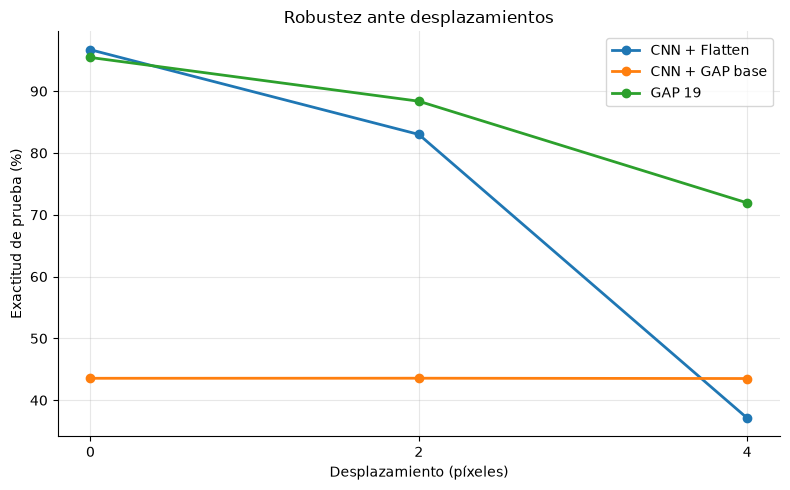

In [39]:
def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Desplazamiento fuera del margen.")

    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)

    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))

    resultado[:, destino_y, destino_x, :] = (
        imagenes[:, origen_y, origen_x, :]
    )
    return resultado


modelos_comparacion = {
    "CNN + Flatten": modelo_flatten,
    "CNN + GAP base": modelo_gap_base,
    "GAP 19": modelo_gap_seleccionado
}

distancias = [0, 2, 4]
resultados = []

for nombre, modelo in modelos_comparacion.items():
    fila = {"Modelo": nombre}

    for d in distancias:
        direcciones = [(0, 0)] if d == 0 else [
            (d, 0), (-d, 0), (0, d), (0, -d)
        ]

        exactitudes = []

        for dy, dx in direcciones:
            imagenes = desplazar(X_prueba, dy, dx)
            pred = modelo.predict(
                imagenes, batch_size=LOTE, verbose=0
            ).argmax(axis=1)

            exactitudes.append(100 * np.mean(pred == y_prueba))

        fila[f"{d} px (%)"] = np.mean(exactitudes)

    fila["Caída a 4 px (pp)"] = (
        fila["0 px (%)"] - fila["4 px (%)"]
    )
    resultados.append(fila)

tabla_desplazamiento = pd.DataFrame(resultados)
display(tabla_desplazamiento.round(2))

# Gráfica
plt.figure(figsize=(8, 5))

for _, fila in tabla_desplazamiento.iterrows():
    plt.plot(
        distancias,
        [fila[f"{d} px (%)"] for d in distancias],
        marker="o",
        linewidth=2,
        label=fila["Modelo"]
    )

plt.xlabel("Desplazamiento (píxeles)")
plt.ylabel("Exactitud de prueba (%)")
plt.title("Robustez ante desplazamientos")
plt.xticks(distancias)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Los resultados muestran que GAP 19 presenta una mayor robustez frente a los desplazamientos que la CNN con Flatten. Aunque Flatten obtuvo una exactitud ligeramente superior sin desplazamiento (96.70% frente a 95.45%), su desempeño disminuyó considerablemente al mover los dígitos.

La diferencia comienza a observarse desde los 2 píxeles, donde GAP 19 alcanzó una exactitud del 88.38 %, frente al 83.00 % de Flatten. A los 4 píxeles, esta diferencia fue todavía más evidente: GAP 19 conservó una exactitud del 71.92 %, mientras que Flatten cayó hasta el 37.11 %. Esto representa una pérdida de 23.53 y 59.59 puntos porcentuales, respectivamente.

Por otro lado, el GAP base prácticamente no presentó cambios en su exactitud, pero se mantuvo alrededor del 43.5 %, lo que demuestra que una menor sensibilidad al desplazamiento no necesariamente implica un mejor desempeño.

En general, los resultados sugieren que **GAP favorece la robustez frente a cambios de posición**, pero necesita una arquitectura adecuada para aprender características suficientemente discriminativas. GAP 19 logró combinar ambas ventajas, manteniendo una exactitud alta en las imágenes originales y conservando un mejor desempeño que Flatten al desplazar los dígitos.

### 5. Conclusiones

El cambio más importante para que la CNN con GAP superara el 95% de exactitud en validación fue modificar la ubicación de las capas MaxPooling. Al distribuirlas entre las convoluciones, en lugar de colocar una sola al final, la exactitud aumentó considerablemente sin necesidad de incrementar los parámetros entrenables.

Después de explorar distintas configuraciones, se seleccionó **GAP 19**, con cuatro capas convolucionales de 8, 20, 20 y 24 filtros. Este modelo alcanzó una exactitud de validación del **95.40 %**, utilizando únicamente **9 754 parámetros**, lo que representa un ahorro de 44 576 parámetros (82.05 %) respecto a la CNN con Flatten.

Finalmente, GAP 19 demostró una mayor robustez frente a los desplazamientos. Aunque Flatten obtuvo una exactitud ligeramente superior en las imágenes originales, GAP 19 comenzó a superarlo desde los **2 píxeles de desplazamiento**, y la diferencia aumentó considerablemente a los 4 píxeles.

En general, los experimentos muestran que no solo importa la cantidad de parámetros de una CNN, sino también cómo se organizan sus capas. Una arquitectura compacta y bien diseñada puede conseguir una buena exactitud y ser más robusta frente a cambios en la posición de las imágenes.

### Referencias
¿Qué son las redes neuronales convolucionales? | IBM. (2026, 26 agosto). https://www.ibm.com/mx-es/think/topics/convolutional-neural-networks

### Declaración de uso de IA
Para el desarrollo de esta práctica se utilizó ChatGPT (OpenAI) como herramienta de apoyo. Los resultados, el código y las interpretaciones obtenidas fueron revisados y ajustados antes de su incorporación a la tarea. 